### ממ"ן 12 (gradients) ב-PyTorch
#### מגיש - Ohad Wolfman 316552496

<div dir="rtl">
<ul>
1א. כתוב בנאי לטנזור אשר דוגם מספרים אקראיים מהתפלגות בדידה שהוא מקבל כקלט, שיחזיר טנזור בגודל size של מספרים אשר נדגמו מההתפלגות dist, כך ש-dist[i] היא ההסתברות לדגום את המספר i
</ul>
</div>

In [112]:
import torch
from torch import autograd


In [113]:
def my_sampler(size,dist,requires_grad=False):
    with torch.no_grad():
        # בדיקת סוג הקלט - טנזור או מערך והמרה לטנזור חדש
        if isinstance(dist, torch.Tensor):
            dist = dist.detach().clone().to(torch.float32)
        else:
            dist = torch.tensor(dist, dtype=torch.float32)
                
        # בדיקת תקינת קלט dist
        dist = torch.as_tensor(dist, dtype=torch.float32)
        if not torch.isclose(dist.sum(),torch.tensor(1.)):
            raise ValueError("The sum of the distribution doesn't equal to 1")
        if (dist < 0).any():
            raise ValueError("At least one probability is negative")

        answer = torch.zeros(size)
        cum = torch.cumsum(dist,dim=0)
        U = torch.rand(size)

        for i in range(len(dist)-1):
            mask = (U >= cum[i])
            answer += mask + 0

    answer.requires_grad_(requires_grad)
    return answer   

בדיקות

In [114]:
print(my_sampler(10, [0.4,0.1,0.3,0.15,0.05]))

tensor([4., 2., 2., 0., 0., 0., 0., 0., 2., 0.])


In [115]:
print(my_sampler((4,1), [0.4,0.1,0.45,0.05]))

tensor([[1.],
        [2.],
        [0.],
        [2.]])


In [116]:
A = my_sampler((2, 8), [0.1, 0.2, 0.7], requires_grad=True)
print(A, A.grad, sep='\n')


tensor([[2., 2., 2., 2., 2., 2., 2., 2.],
        [2., 2., 2., 1., 2., 2., 1., 2.]], requires_grad=True)
None


<div dir="rtl">
<ul>
1ב. דגמו 10K משתנים מקריים מההתפלגות [0.1,0.2,0.7] וציירו היסטוגרמה של הדגימות
</ul>
</div>

In [117]:
import matplotlib.pyplot as plt
import numpy as np

In [118]:
samples = my_sampler(10000, [0.1, 0.2, 0.7])

def plot_hist(samples, num_classes):
    # המרת הטנזור למערך נאמפיי
    data = samples.detach() # ננתק את הטנזור מהאוטוגראד על ידי דיטאץ'
    data = data.cpu().numpy() # העברה לזיכרון המעבד והמרה למערך נאמפיי
    data = data.flatten() # שיטוח למימד אחד

    bins = np.arange(num_classes+1) - 0.5 # הורדנו 0.5 כדי למקם את השנתות במרכז הבין

    plt.hist(data,bins,density=True, rwidth=0.5)
    plt.xticks(range(num_classes))
    plt.ylabel('Probability')
    plt.title('10K samples probability')
    plt.grid(axis='y', linestyle='--')
    plt.show()


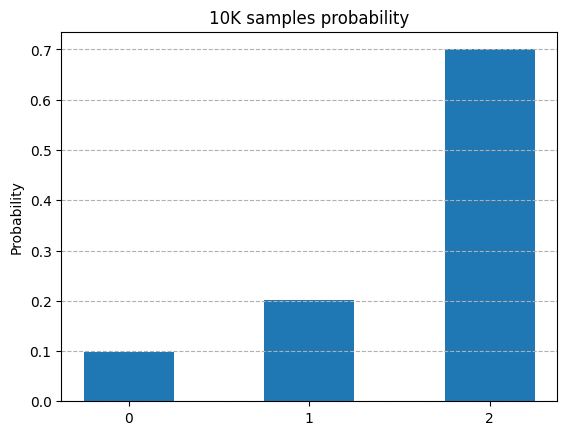

In [119]:
dist = torch.Tensor([0.1, 0.2, 0.7])
A = my_sampler(10000, dist, requires_grad=True)
plot_hist(A,len(dist))

<div dir="rtl">
<ul>
ב. עליך לממש מערכת גזירה אוטומטית. על המערכת לעקוב אחרי פעולות החשבון המתבצעות על המשתנים ולחשב יחד עם כל פעולה את הנגזרת המיידית שלה: הנגזרת של הפלט לפי הקלט. לבסוף יהיה על המערכת לחשב נגזרות לפי כלל השרשרת
</ul>
</div>

In [120]:
class MyScalar:
    def __init__(self, value, grad=0, parent=None):
        self.value = value
        self.grad = grad
        self.parent = parent

    # עבור מקרים של סקלר בודד - לא נדרש בתרגיל אבל לשם האסטתיקה
    def __repr__(self):
        return f"MyScalar({self.value})"


In [121]:
def add(a, n):
    return MyScalar(value = a.value + n, grad = 1, parent = a)

def power(a, n):
    return MyScalar(value=torch.pow(a.value, n), grad = n*torch.pow(a.value, n-1), parent=a)

def sin(a):
    return MyScalar(value = torch.sin(a.value), grad =torch.cos(a.value), parent = a)

def cos(a):
    return MyScalar(value = torch.cos(a.value), grad = -(torch.sin(a.value)), parent = a)

def ln(a):
    return MyScalar(value = torch.log(a.value), grad = torch.div(1,a.value), parent = a)

def exp(a):
    return MyScalar(value = torch.exp(a.value), grad = torch.exp(a.value), parent = a)

def mul(a, n):
    return MyScalar(value = torch.mul(a.value, n), grad=n, parent=a)

In [122]:
def get_gradient(a):
    grads = {}
    grads[a] = 1

    node = a
    while node.parent is not None:
        grads[node.parent] = grads[node] * node.grad
        node = node.parent
    return grads

בדיקות

In [123]:
get_gradient(MyScalar(8))

{MyScalar(8): 1}

In [124]:
a = MyScalar(torch.tensor(2.0))
b = power(a, 2)
c = exp(b)
d = get_gradient(c)
print(d[c], d[b], d[a], sep="\n")


1
tensor(54.5981)
tensor(218.3926)


In [125]:
a = MyScalar(torch.tensor(2.0))
b = mul(a, 5)        # 5a
c = add(b, 3)        # 5a + 3
d = get_gradient(c)
print(d[c], d[b], d[a], sep="\n")

1
1
5


In [ ]:
a = MyScalar(torch.tensor(0.0))
b = sin(a)           # sin(0) = 0
c = cos(b)           # cos(0) = 1
d = get_gradient(c)
print(d[c], d[b], d[a], sep="\n")

1
tensor(-0.)
tensor(-0.)
